# Monte Carlo

## Modules

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime, timedelta

## Historical Data

In [5]:

# Historical FCF data
years = [2019, 2020, 2021, 2022, 2023]
fcf_values = [-226, 0, 157, 796, 355]  # Negative free cash flow included

# Base case projections for FCF from 2024 to 2030
base_case_years = list(range(2024, 2031))  # Updated to include 2024 to 2030 (7 years)
base_case_fcf = [253,287,346,359,372,385,396]

# Monte Carlo Simulation parameters
num_simulations = 1000000
num_years_forecast = len(base_case_fcf)

# Calculate mean and standard deviation from historical data
mean_fcf = np.mean(fcf_values)
std_fcf = np.std(fcf_values)

## Run the Monte Carlo

In [6]:


# Run Monte Carlo Simulation
forecasted_fcf = []
for _ in range(num_simulations):
    forecast = []
    for i in range(num_years_forecast):
        # Use the base case value as the mean for each year's forecast
        base_fcf = base_case_fcf[i]
        next_fcf = np.random.normal(base_fcf, std_fcf)
        forecast.append(next_fcf)  # Ensure FCF is non-negative
    forecasted_fcf.append(forecast)

# Calculate average forecasted FCF for each year
average_forecast = np.mean(forecasted_fcf, axis=0)



## Plot the Monte Carlo

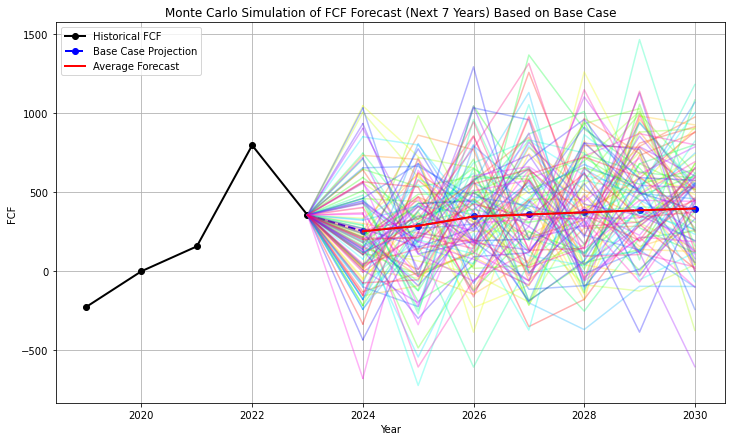

In [7]:

# Plot the historical and forecasted FCF
plt.figure(figsize=(12, 7))
cmap = plt.get_cmap('hsv')

# Plot historical FCF
plt.plot(years, fcf_values, color='black', linewidth=2, marker='o', label='Historical FCF')

# Connect historical FCF to base case projection
plt.plot([2023, 2024], [fcf_values[-1], base_case_fcf[0]], color='blue', linewidth=2, linestyle='--')

# Plot base case projection
plt.plot(base_case_years, base_case_fcf, color='blue', linewidth=2, linestyle='--', marker='o', label='Base Case Projection')


# Plot a random sample of 100 forecasted FCF and connect 2023 to 2024
random_indices = np.random.choice(num_simulations, 100, replace=False)
for count, i in enumerate(random_indices):
    plt.plot([2023, 2024], [fcf_values[-1], forecasted_fcf[i][0]], color=cmap(count / 100), alpha=0.3)
    plt.plot(base_case_years, forecasted_fcf[i], color=cmap(count / 100), alpha=0.3)

# Plot average forecast
plt.plot(base_case_years, average_forecast, color='red', linewidth=2, label='Average Forecast')

plt.xlabel('Year')
plt.ylabel('FCF')
plt.title('Monte Carlo Simulation of FCF Forecast (Next 7 Years) Based on Base Case')  # Updated title
plt.legend()
plt.grid()
plt.show()



## DCF Calculations

In [8]:
# Discounted Cash Flow parameters
discount_rate = 0.069  # WACC
terminal_growth_rate = 0.02  # Assume 2% terminal growth rate
value_of_cash = 365  # Cash on balance sheet
value_of_debt = 3533.8778  # Debt on balance sheet
shares_outstanding = 25136  # Shares outstanding

# Calculate the present value of forecasted FCF for each simulation
total_pv_simulations = []
for forecast in forecasted_fcf:
    pv_forecast = 0
    for year in range(num_years_forecast):
        discount_factor = (1 + discount_rate) ** (year + 1)
        pv_forecast += forecast[year] / discount_factor
    terminal_value = forecast[-1] * (1 + terminal_growth_rate) / (discount_rate - terminal_growth_rate)
    pv_terminal_value = terminal_value / ((1 + discount_rate) ** num_years_forecast)
    total_pv_simulations.append(pv_forecast + pv_terminal_value)

# Calculate the average DCF valuation
average_dcf_valuation = np.mean(total_pv_simulations)
equity_value = average_dcf_valuation + value_of_cash - value_of_debt
implied_share_price = equity_value / shares_outstanding


## Price Data

In [9]:
ticker = "TPR"  # Ticker we are looking at

# Retrieve data for the ticker
stock_data = yf.download(
    ticker,
    start=(datetime.today() - timedelta(days=7)),
    end=(datetime.today()),
    interval="1d"
)

# Ensure current_share_price is a float
current_share_price = stock_data['Adj Close'].iloc[-1]
current_share_price = float(current_share_price)
print(f"Current Share Price: ${current_share_price:.2f}")


print(f"Average DCF Valuation: ${average_dcf_valuation:,.2f}")
print(f"Implied Share Price (ISP): ${implied_share_price:,.2f}")



[*********************100%***********************]  1 of 1 completed

Current Share Price: $60.92
Average DCF Valuation: $6,985.10
Implied Share Price (ISP): $0.15


## Percentiles

In [10]:
# Calculate implied share price percentiles
percentiles = [95, 75, 50, 25, 5]
percentile_values = np.percentile(total_pv_simulations, percentiles)
percentile_prices = (percentile_values + value_of_cash - value_of_debt) / shares_outstanding

# Create a table of percentiles and implied prices
print("\nPercentile\t  Price \t Upside")
for i, p in enumerate(percentiles):
    price = max(0,percentile_prices[i])
    discount = ((price - current_share_price) / current_share_price) * 100
    print(f"{p}th  \t\t ${price:,.2f}\t \t{discount:.2f}%")


Percentile	  Price 	 Upside
95th  		 $0.46	 	-99.24%
75th  		 $0.28	 	-99.54%
50th  		 $0.15	 	-99.75%
25th  		 $0.02	 	-99.96%
5th  		 $0.00	 	-100.00%


## Box Plots

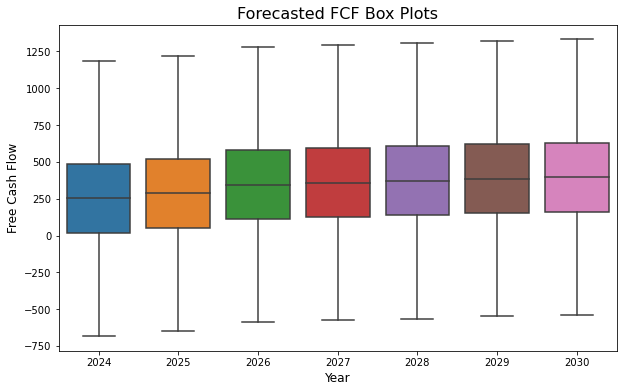

In [11]:
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a list of forecasted FCFs per year
fcf_per_year = [[] for _ in range(num_years_forecast)]

# Transpose the forecasted FCF data to get data per year
for simulation in forecasted_fcf:
    for year_idx in range(num_years_forecast):
        fcf_per_year[year_idx].append(simulation[year_idx])

# Plot the box plots excluding outliers
plt.figure(figsize=(10, 6))
sns.boxplot(data=fcf_per_year, showfliers=False)  # Exclude outliers

# Customize the plot with title and labels
plt.title('Forecasted FCF Box Plots', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Free Cash Flow', fontsize=12)

# Set the x-axis labels to the forecast years
plt.xticks(ticks=range(num_years_forecast), labels=base_case_years)

# Show the plot
plt.show()


In [12]:
import numpy as np

# Calculate and print the standard deviation for each year
std_devs = [np.std(year_data) for year_data in fcf_per_year]

print("\n   Monte Carlo Standard Deviation\n")

# Print the standard deviations with the corresponding year labels
for year, std_dev in zip(base_case_years, std_devs):
    print(f"\tYear {year}: {std_dev:.2f}")

print("\n   Average Std Dev = ",round(np.mean(std_devs),2))


   Monte Carlo Standard Deviation

	Year 2024: 346.78
	Year 2025: 346.70
	Year 2026: 347.02
	Year 2027: 346.46
	Year 2028: 346.81
	Year 2029: 346.64
	Year 2030: 346.53

   Average Std Dev =  346.7


In [13]:

# Calculate the medians for each year
medians = [np.median(fcf_data) for fcf_data in fcf_per_year]

# Calculate the percentage change of the median from year to year
percentage_changes = [
    ((medians[i] - medians[i - 1]) / medians[i - 1]) * 100
    for i in range(1, len(medians))
]

# Print the percentage changes
print("\nYear-to-Year Median Percentage Changes:\n")
for i, pct_change in enumerate(percentage_changes, start=1):  # Start indexing from 1 for year 2 onward
    print(f"From {base_case_years[i - 1]} to {base_case_years[i]}: {pct_change:.2f}%")

print(f"\nAverage Percentage Change = {round(np.mean(percentage_changes),2)}%")



Year-to-Year Median Percentage Changes:

From 2024 to 2025: 13.58%
From 2025 to 2026: 20.49%
From 2026 to 2027: 3.92%
From 2027 to 2028: 3.37%
From 2028 to 2029: 3.82%
From 2029 to 2030: 2.74%

Average Percentage Change = 7.99%


## Skewness

In [14]:
import pandas as pd
from scipy.stats import skew

# Prepare data for DataFrame
data = []
for year_idx in range(num_years_forecast):
    year = base_case_years[year_idx]
    fcf_values = fcf_per_year[year_idx]
    median = np.median(fcf_values)
    percentile_25 = np.percentile(fcf_values, 25)
    percentile_75 = np.percentile(fcf_values, 75)
    skewness = skew(fcf_values)
    data.append({
        'Year': year,
        'Median': median,
        '25th Percentile': percentile_25,
        '75th Percentile': percentile_75,
        'Skewness': skewness
    })

# Create DataFrame
df = pd.DataFrame(data)

# Display DataFrame
print(df)

# Save the DataFrame to a CSV file
csv_file_name = "forecasted_fcf_percentiles.csv"
df.to_csv(csv_file_name, index=False)

print(f"DataFrame saved to {csv_file_name}")


   Year      Median  25th Percentile  75th Percentile  Skewness
0  2024  252.503085        18.806856       486.289124  0.003185
1  2025  286.782483        52.926495       520.592269  0.001741
2  2026  345.531011       111.891225       579.195940  0.001257
3  2027  359.059931       125.126970       592.322536 -0.000772
4  2028  371.165506       137.947499       606.216976 -0.003130
5  2029  385.356509       151.582037       619.048193 -0.000867
6  2030  395.914474       162.143063       629.894194  0.002721
DataFrame saved to forecasted_fcf_percentiles.csv


In [15]:
import scipy.stats as stats
import numpy as np

# Transpose the forecasted FCF data to get data per year
fcf_per_year = np.array(forecasted_fcf).T  # Each row now represents a year

# Calculate and print skewness for each year
for year_idx, year in enumerate(base_case_years):
    data = fcf_per_year[year_idx]
    skew_value = stats.skew(data)
    print(f"Skewness for {year}: {skew_value}")

# Calculate the average skewness across all years
average_skewness = np.mean([stats.skew(fcf_per_year[year_idx]) for year_idx in range(num_years_forecast)])
print(f"\nAverage Skewness: {average_skewness}")


Skewness for 2024: 0.003185068051226931
Skewness for 2025: 0.0017405407139348898
Skewness for 2026: 0.001257425834157711
Skewness for 2027: -0.0007723951203410246
Skewness for 2028: -0.003129707270757179
Skewness for 2029: -0.0008670933005227594
Skewness for 2030: 0.00272147760964094

Average Skewness: 0.0005907595024770727
